In [1]:
using DynamicEnergy.ChilledWater: WaterPort, Boundary_pT, 
								MixingVolume, PressureDrop, Pump_dp, 
								Pump_curve, CheckValve_equalPercentage,
								ChillerQcapPoly, PolyCOP
using DynamicEnergy: @deindex
using ModelingToolkitStandardLibrary.Blocks: LimPI, Constant
using ModelingToolkit: equations, observed, parameters, mtkcompile, connect, System, instream
using ModelingToolkit: @parameters, @named
using ModelingToolkit: t_nounits as t

ERROR: LoadError: ArgumentError: Cannot load (`using/import`) module ModelingToolkitStandardLibrary into module DynamicEnergy.ChilledWater in package DynamicEnergy
because package DynamicEnergy does not have ModelingToolkitStandardLibrary in its dependencies:
- You may have a partially installed environment. Try `Pkg.instantiate()`
  to ensure all packages in the environment are installed.
- Or, if you have DynamicEnergy checked out for development and have
  added ModelingToolkitStandardLibrary as a dependency but haven't updated your primary
  environment's manifest file, try `Pkg.resolve()`.
- Otherwise you may need to report an issue with DynamicEnergy
Stacktrace:
  [1] macro expansion
    @ .\loading.jl:2522 [inlined]
  [2] macro expansion
    @ .\lock.jl:376 [inlined]
  [3] __require(into::Module, mod::Symbol)
    @ Base .\loading.jl:2502
  [4] require
    @ .\loading.jl:2478 [inlined]
  [5] eval_import_path
    @ .\module.jl:36 [inlined]
  [6] eval_import_path_all(at::Module, pa

Base.Precompilation.PkgPrecompileError: The following 1 package failed to precompile:

DynamicEnergy 
Failed to precompile DynamicEnergy [550abdf0-07c2-484a-b92b-327d5b0284c7] to "C:\\Users\\80983\\.julia\\compiled\\v1.13\\DynamicEnergy\\jl_3067.tmp" (ProcessExited(1)).


In [2]:
settings = (
    inlet_T = 313.15, initial_T = 293.15, volume = 1.0,
    density = 997.0, specific_heat = 4186.0,
    boundary_p = 101325.0, pump_dp = 100000.0,
    nominal_flow = 50.0, nominal_dp = 674412.8761,
    tspan = (0.0, 3600.0), reltol = 1e-8, abstol = 1e-8, dtmax = 2.0,
)
# Pump curve
ρ = 997.0
V_flows = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200,
           1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2100, 2200,
           2300, 2400, 2500] # m3/h
Hs      = [72.78, 72.17, 71.60, 71.03, 70.48, 69.92, 69.35, 68.74, 68.10, 67.41,
           66.66, 65.83, 64.92, 63.92, 62.81, 61.58, 60.23, 58.73, 57.09, 55.28,
           53.30, 51.13, 48.77, 46.19, 43.41, 40.39] # m
P_elec_kW    = [0.0, 35.8, 68.7, 98.8, 126.4, 151.6, 174.8, 196.0, 215.3, 232.5,
             248.3, 262.8, 276.2, 288.5, 300.5, 313.2, 324.8, 334.9, 341.6, 343.7,
             345.6, 348.2, 351.0, 354.1, 357.6, 361.4] # kW
m_flows_data = V_flows.* ρ ./3600 # m3/h -> kg/h -> kg/s
dPs_data = Hs.* ρ .* 9.81 # m -> Pa
power_data = P_elec_kW .* 1000 # kW -> W
# display(m_flows_data)
# display(dPs_data)
# @parameters heat_flux::Float64 = -420000.0
# Chiller pars
chiller_params = (;
    QclgNml       = 6e5,                       # W，装机冷量（= 设计点 CAPFT 1.0 时）
    TevapOutNml   = 38.0 + 273.15,               # K，名义蒸发器出水
    TcondInNml    = 45.0 + 273.15,               # K，名义冷凝器进水
    TevapOutBound = [35.0 + 273.15, 41.0 + 273.15],   # K，单调性校核区间 (x ∈ [-3, +3])
    TcondInBound  = [42.0 + 273.15, 48.0 + 273.15],   # K，(y ∈ [-3, +3])
    c             = [0.025, -0.0008, -0.02, 0.0, 0.0], # c1..c5
    CAP_min       = 0.5,
    eps_mFlow     = 1e-6,
)
cop_params = (;
    COPatFull     = 6.00,             # 满载 (LR=1)、名义 38/45 °C 时的 COP
    COPatPeak     = 6.90,             # 部分负荷峰值 COP（1.15 × 满载）
    LRpeakCOP     = 0.65,             # 峰值所在负荷率
    TevapCOPratio = 1.020,            # 蒸发器出水每 +1 K  → COP ×1.020
    TcondCOPratio = 1.025,            # 冷凝器进水每 +1 K → COP ÷1.025
    TevapOutNml   = 38.0 + 273.15,    # 【必须】= chiller_params.TevapOutNml
    TcondInNml    = 45.0 + 273.15,    # 【必须】= chiller_params.TcondInNml
    COPmin        = 2.50,             # 下限护栏
    COPmax        = 12.0,             # 上限护栏
)
nP = 3
systems = @named begin
    Source = Boundary_pT(p = settings.boundary_p, T = settings.inlet_T)
	Source_clg = Boundary_pT(p = 45 + 273.15, T = settings.inlet_T)
    Sink = Boundary_pT(p = settings.boundary_p, T = settings.initial_T)
	Pump[1:nP] = Pump_curve(m_flows_data = m_flows_data, dPs_data = dPs_data, power_data = power_data)

	Pipe[1:nP] = PressureDrop(nominalFlowRate = settings.nominal_flow,
        nominalPressureDrop = settings.nominal_dp)
	CheckValve[1:nP] = CheckValve_equalPercentage(nominalFlowRate = settings.nominal_flow,
        nominalPressureDrop = settings.nominal_dp)
	Chiller[1:nP] = ChillerQcapPoly(; chiller_params...)
	COP[1:nP] = PolyCOP(;cop_params...)
    Tank = MixingVolume(volume = settings.volume, T_init = settings.initial_T, use_heat_flux = true, nPorts = 4)
	controller = LimPI(; k = 0.02, T = 20, Ta = 40, u_max = 1, u_min = 1e-6)
end
nstate = [true, true, false]
@deindex connections = [
	# Chilled water loop
	[connect(Source.port, Pump[i].port_1) for i in 1:nP]...,
	[connect(Pump[i].port_2, Pipe[i].port_1) for i in 1:nP]...,
	[connect(Pipe[i].port_2, Chiller[i].port_1) for i in 1:nP]...,
	[connect(Chiller[i].port_2, CheckValve[i].port_1) for i in 1:nP]...,
	[connect(CheckValve[i].port_2, Tank.port[i]) for i in 1:nP]...,
	connect(Tank.port[nP + 1], Sink.port),
	# Cooling water loop
	[connect(Source_clg.port, Chiller[i].port_3) for i in 1:nP]...,
	[connect(Chiller[i].port_4, Sink.port) for i in 1:nP]...,
	[Chiller[i].port_3.mFlow ~ Chiller[i].port_1.mFlow for i in 1:nP]...,
	[Chiller[i].port_1.p ~ Chiller[i].port_2.p for i in 1:nP]...,
	# COP model
	[COP[i].LR ~ Chiller[i].LR for i in 1:nP]...,
	[COP[i].TcondIn ~ Chiller[i].TcondIn for i in 1:nP]...,
	[COP[i].TevapOut ~ Chiller[i].TevapOut for i in 1:nP]...,
	# Tank heat input
	Tank.flux_input ~ 420000.0,
	# control pump speed
	[1 ~ Pump[i].u for i in 1:nP]...,
	# control valve opening
    controller.err_input.u ~ (Tank.T - (30 + 273.15)),
	[nstate[i] ? CheckValve[i].u ~ controller.ctr_output.u : CheckValve[i].u ~ 0 for i in 1:nP]...,
]
@named raw_model = System(connections, t, [], [];
    systems = systems)
sys = mtkcompile(raw_model)
display(sys)
println("\nParameters:")
foreach(println, parameters(sys))
println("\nEquations:")
foreach(println, equations(sys))
println("\nObserved:",)
foreach(println, observed(sys))

using ModelingToolkit: ODEProblem, solve
using DifferentialEquations
prob = ODEProblem(sys, [Tank.T => 30 + 273.15], settings.tspan)
display(prob)
display(prob.f.mass_matrix)

Model raw_model:
Equations (12):
  12 standard: see equations(raw_model)
Unknowns (12): see unknowns(raw_model)
  controller₊addPI₊input2₊u(t): Inner variable in RealInput input2
  Tank₊T(t)
  CheckValve_2₊port_1₊mFlow(t)
  CheckValve_3₊port_1₊mFlow(t)
  ⋮
Parameters (71): see parameters(raw_model)
  Chiller_1₊c1
  Chiller_1₊c2
  Chiller_1₊c3
  Chiller_1₊c4
  ⋮
Observed (171): see observed(raw_model)


Parameters:
Chiller_1₊c1
Chiller_1₊c2
Chiller_1₊c3
Chiller_1₊c4
Chiller_1₊c5
Chiller_1₊TevapOutNml
Chiller_1₊TcondInNml
Chiller_1₊QclgNml
Chiller_1₊CAP_min
Chiller_2₊c1
Chiller_2₊c2
Chiller_2₊c3
Chiller_2₊c4
Chiller_2₊c5
Chiller_2₊TevapOutNml
Chiller_2₊TcondInNml
Chiller_2₊QclgNml
Chiller_2₊CAP_min
Chiller_3₊c1
Chiller_3₊c2
Chiller_3₊c3
Chiller_3₊c4
Chiller_3₊c5
Chiller_3₊TevapOutNml
Chiller_3₊TcondInNml
Chiller_3₊QclgNml
Chiller_3₊CAP_min
COP_1₊COPatFull
COP_1₊COPatPeak
COP_1₊LRpeakCOP
COP_1₊TevapCOPratio
COP_1₊TcondCOPratio
COP_1₊TevapOutNml
COP_1₊TcondInNml
COP_1₊COPmin
COP_1₊COPmax
COP_2₊COPatFull
COP_2₊COPatPeak
COP_2₊LRpeakCOP
COP_2₊TevapCOPratio
COP_2₊TcondCOPratio
COP_2₊TevapOutNml
COP_2₊TcondInNml
COP_2₊COPmin
COP_2₊COPmax
COP_3₊COPatFull
COP_3₊COPatPeak
COP_3₊LRpeakCOP
COP_3₊TevapCOPratio
COP_3₊TcondCOPratio
COP_3₊TevapOutNml
COP_3₊TcondInNml
COP_3₊COPmin
COP_3₊COPmax
controller₊k
controller₊T
controller₊Ta
controller₊u_max
controller₊u_min
controller₊gainPI₊u_start
controll

ODEProblem with uType Vector{Float64} and tType Float64. In-place: true
Initialization status: FULLY_DETERMINED
Non-trivial mass matrix: true
timespan: (0.0, 3600.0)
u0: 12-element Vector{Float64}:
      0.0
    303.15
      0.0
      0.0
      0.0
      0.44879377873244264
 300000.0
  83720.0
      0.3729220089062045
  83720.0
      0.4627468194490765
  83720.0

12×12 LinearAlgebra.Diagonal{Float64, Vector{Float64}}:
 1.0   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅   1.0   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅   0.0   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅   0.0   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅   0.0   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅   0.0   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   0.0   ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   0.0   ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   0.0   ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   0.0   ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   0.0   ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   0.0

In [3]:

# sol = solve(
#     prob,
#     Rodas5P();
#     abstol = 1e-9,
#     reltol = 1e-8
# )
sol = solve(prob; reltol = settings.reltol, abstol = settings.abstol, dtmax = 10)

retcode: Success
Interpolation: 3rd order Hermite
t: 419-element Vector{Float64}:
    0.0
    1.0e-6
    7.837123065868898e-6
    5.458337488370542e-5
    0.0003741932136346662
    0.0025594047558237785
    0.0062652790972950265
    0.027187371095657747
    0.1278884407454331
    0.5900956846400174
    ⋮
 3527.2755185740725
 3537.2755185740725
 3547.2755185740725
 3557.2755185740725
 3567.2755185740725
 3577.2755185740725
 3587.2755185740725
 3597.2755185740725
 3600.0
u: 419-element Vector{Vector{Float64}}:
 [0.0, 303.15, 1.0269996590497839, 1.0269996590497839, 1.0269996590497839, 141867.67890181448, 300000.0, 197579.1999999966, 141867.6789018214, 197579.20000000007, 141867.67890182105, 197579.2000000042]
 [1.9886321166006577e-15, 303.15000002956015, 1.0269996590497843, 1.0269996590497843, 1.0269996590497843, 141867.6789018191, 300000.0, 197579.2000742433, 141867.6789018191, 197579.2000742433, 141867.6789018191, 197579.2000742433]
 [5.5163660183031456e-14, 303.1500002316666, 1.0269996

In [4]:
# integrator = init(prob, Rodas5P())
# @show integrator.u
# for i in 1:500
#     step!(integrator)
#     if any(isnan, integrator.u)
#         println("NaN at t = ", integrator.t, "  u = ", integrator.u)
#         break
#     end
# end

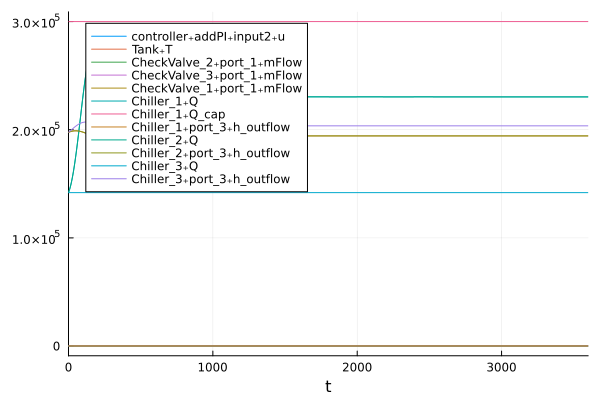

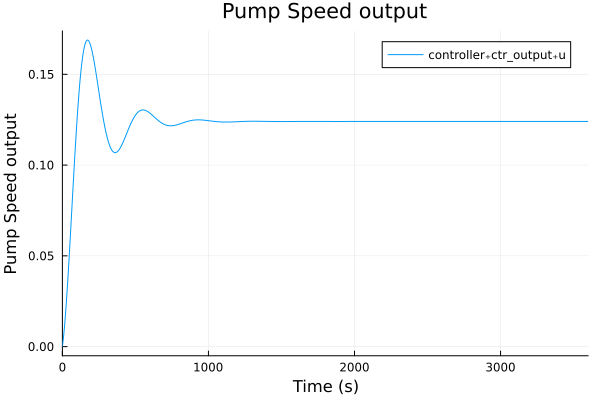

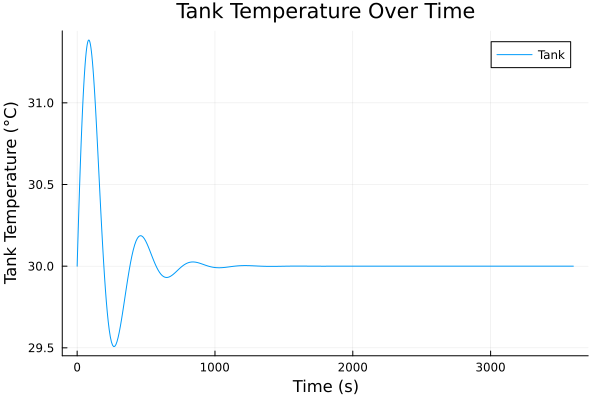

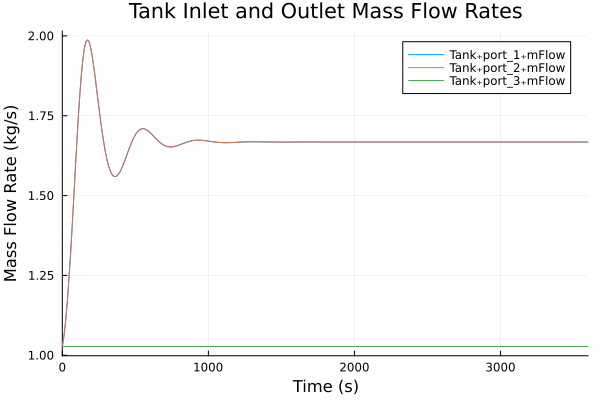

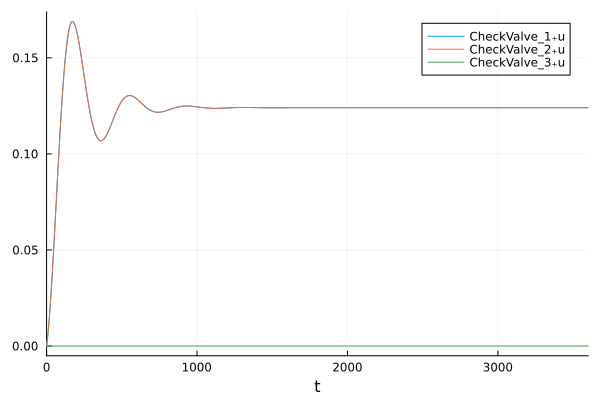

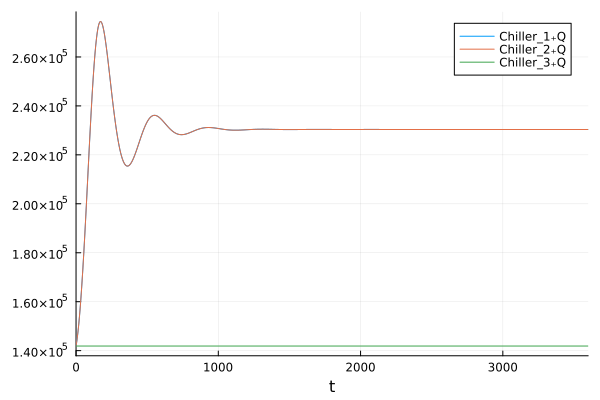

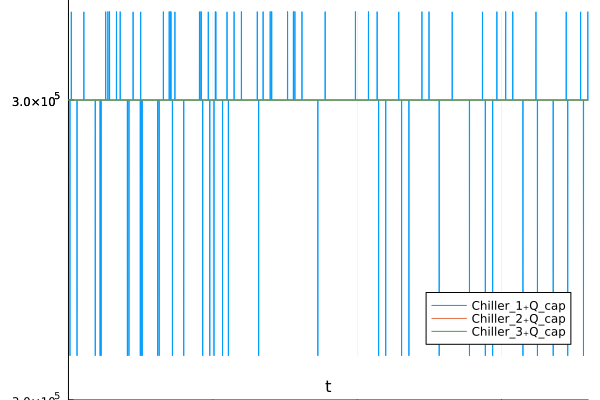

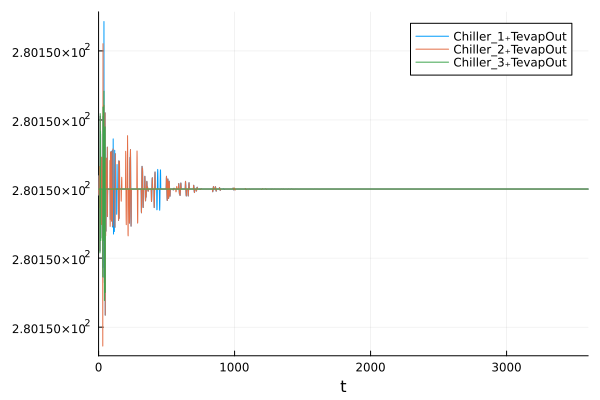

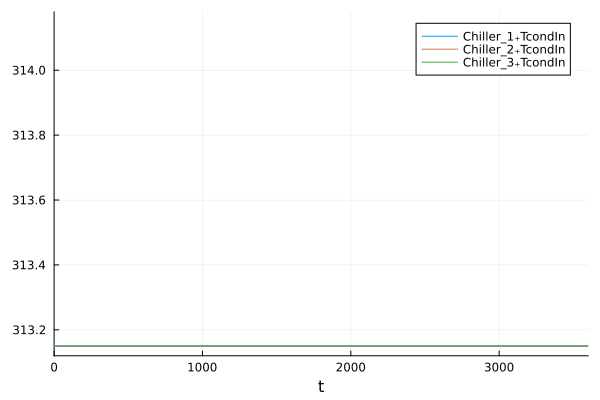

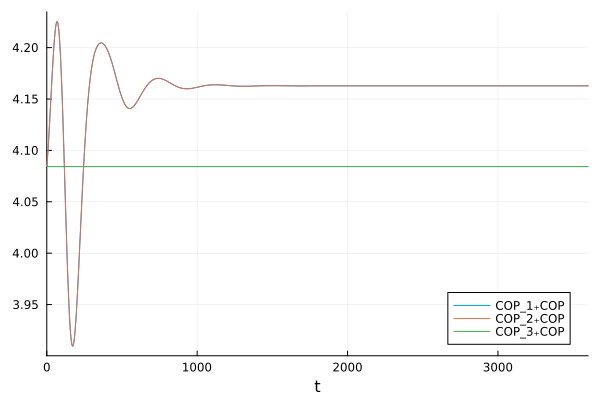

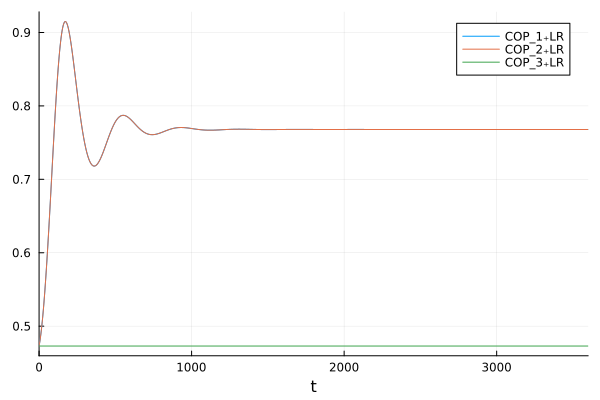

GKS: Possible loss of precision in routine SET_WINDOW


In [5]:
using Plots: plot
plot(Tank.port_3.mFlow)
display(plot(sol))
# display(plot(sol; idxs = [flux_controller.ctr_output.u], xlabel = "Time (s)", ylabel = "Heat flux output (W)", title = "Heat Flux output"))
display(plot(sol; idxs = [controller.ctr_output.u], xlabel = "Time (s)", ylabel = "Pump Speed output", title = "Pump Speed output"))
display(plot(sol.t, sol[Tank.T] .- 273.15;
     xlabel = "Time (s)", ylabel = "Tank Temperature (°C)",
     label = "Tank", title = "Tank Temperature Over Time"))
# display(plot(sol; idxs = [Pipe.port_1.mFlow], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Pipe Inlet Mass Flow Rate"))
display(plot(sol; idxs = [Tank.port_1.mFlow, Tank.port_2.mFlow, Tank.port_3.mFlow], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Tank Inlet and Outlet Mass Flow Rates"))
# display(plot(sol; idxs = [portof(Tank, i) for i in 1:3], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Tank Inlet and Outlet Mass Flow Rates"))
display(plot(sol; idxs = [CheckValve[i].u for i in 1:3]))
display(plot(sol; idxs = [Chiller[i].Q for i in 1:3]))
display(plot(sol; idxs = [Chiller[i].Q_cap for i in 1:3]))
display(plot(sol; idxs = [Chiller[i].TevapOut for i in 1:3]))
display(plot(sol; idxs = [Chiller[i].TcondIn for i in 1:3]))
display(plot(sol; idxs = [COP[i].COP for i in 1:3]))
display(plot(sol; idxs = [COP[i].LR for i in 1:3]))

In [6]:
ts = collect(0.0:10.0:600.0)

vars = [Tank.T, Pipe[1].port_1.mFlow, Tank.port_1.mFlow, Tank.port_2.mFlow]

data = hcat([sol(t; idxs = vars) for t in ts]...)
display(data)
data = permutedims(data)
display(data)
data_with_time = hcat(ts, data)
display(data_with_time)

column_name = ["Time (s)", "Tank Temperature (K)", "Pipe Inlet Mass Flow Rate (kg/s)", "Tank Inlet Mass Flow Rate (kg/s)", "Tank Outlet Mass Flow Rate (kg/s)"]

using DataFrames
df = DataFrame(data_with_time, Symbol.(column_name))
display(df)

4×61 Matrix{Float64}:
 303.15   303.435    303.695    303.926    …  303.138   303.122   303.109
   1.027    1.05606    1.09549    1.14478       1.7049    1.7015    1.69747
   1.027    1.05606    1.09549    1.14478       1.7049    1.7015    1.69747
   1.027    1.05606    1.09549    1.14478       1.7049    1.7015    1.69747

61×4 Matrix{Float64}:
 303.15   1.027    1.027    1.027
 303.435  1.05606  1.05606  1.05606
 303.695  1.09549  1.09549  1.09549
 303.926  1.14478  1.14478  1.14478
 304.125  1.20328  1.20328  1.20328
 304.287  1.27011  1.27011  1.27011
 304.409  1.34401  1.34401  1.34401
 304.491  1.42331  1.42331  1.42331
 304.531  1.50591  1.50591  1.50591
 304.529  1.58931  1.58931  1.58931
   ⋮                        
 303.261  1.70248  1.70248  1.70248
 303.239  1.70629  1.70629  1.70629
 303.217  1.7086   1.7086   1.7086
 303.196  1.70949  1.70949  1.70949
 303.175  1.70907  1.70907  1.70907
 303.156  1.70748  1.70748  1.70748
 303.138  1.7049   1.7049   1.7049
 303.122  1.7015   1.7015   1.7015
 303.109  1.69747  1.69747  1.69747

61×5 Matrix{Float64}:
   0.0  303.15   1.027    1.027    1.027
  10.0  303.435  1.05606  1.05606  1.05606
  20.0  303.695  1.09549  1.09549  1.09549
  30.0  303.926  1.14478  1.14478  1.14478
  40.0  304.125  1.20328  1.20328  1.20328
  50.0  304.287  1.27011  1.27011  1.27011
  60.0  304.409  1.34401  1.34401  1.34401
  70.0  304.491  1.42331  1.42331  1.42331
  80.0  304.531  1.50591  1.50591  1.50591
  90.0  304.529  1.58931  1.58931  1.58931
   ⋮                               
 520.0  303.261  1.70248  1.70248  1.70248
 530.0  303.239  1.70629  1.70629  1.70629
 540.0  303.217  1.7086   1.7086   1.7086
 550.0  303.196  1.70949  1.70949  1.70949
 560.0  303.175  1.70907  1.70907  1.70907
 570.0  303.156  1.70748  1.70748  1.70748
 580.0  303.138  1.7049   1.7049   1.7049
 590.0  303.122  1.7015   1.7015   1.7015
 600.0  303.109  1.69747  1.69747  1.69747

Row,Time (s),Tank Temperature (K),Pipe Inlet Mass Flow Rate (kg/s),Tank Inlet Mass Flow Rate (kg/s),Tank Outlet Mass Flow Rate (kg/s)
,Float64,Float64,Float64,Float64,Float64
1,0.0,303.15,1.027,1.027,1.027
2,10.0,303.435,1.05606,1.05606,1.05606
3,20.0,303.695,1.09549,1.09549,1.09549
4,30.0,303.926,1.14478,1.14478,1.14478
5,40.0,304.125,1.20328,1.20328,1.20328
6,50.0,304.287,1.27011,1.27011,1.27011
7,60.0,304.409,1.34401,1.34401,1.34401
8,70.0,304.491,1.42331,1.42331,1.42331
9,80.0,304.531,1.50591,1.50591,1.50591
